# Chatbot odontológico: preprocesamiento de datos para clasificar urgencias dentales en español

**Dataset:** [`Wildstash/dental-treatment-planning-2.5k`](https://huggingface.co/datasets/Wildstash/dental-treatment-planning-2.5k) (casos clínicos sintéticos en inglés, licencia Apache 2.0).
**Objetivo:** convertirlo en un dataset limpio, en español, con etiquetas `0 = Electivo`, `1 = Moderado`, `2 = Urgente`, listo para entrenar un clasificador (TF-IDF + Logistic Regression / Naive Bayes / Linear SVM).

> **Aviso:** el sistema ofrece orientación inicial y clasificación de urgencia. No sustituye el diagnóstico de un profesional odontológico.

**Antes de empezar**
1. Menú *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*. Solo la Fase 3 (traducción) lo aprovecha; con CPU funciona, pero tarda bastante más.
2. Ejecuta las celdas en orden. Todas las cifras que aparecen (incluidas las de la Fase 8) salen de la ejecución real; ninguna está escrita a mano.
3. Los archivos se guardan en `/content/salida/`.

| Fase | Contenido |
|---|---|
| 1 | Descarga y exploración |
| 2 | Extracción de síntomas y urgencia |
| 3 | Traducción al español |
| 4 | Limpieza y preprocesamiento |
| 5 | Análisis exploratorio |
| 6 | Preparación para entrenamiento |
| 7 | Exportación de CSV |
| 8 | Resumen técnico para el informe |

## FASE 1. Descarga y exploración del dataset

### 1.0 Instalación e importaciones
Colab ya trae `pandas`, `scikit-learn`, `matplotlib` y `seaborn`. Instalamos `datasets` (descarga desde Hugging Face), `transformers` + `sentencepiece` + `sacremoses` (modelo de traducción de la Fase 3).

In [16]:
!pip -q install datasets transformers sentencepiece sacremoses

In [17]:
# [CELDA 1.0] Importaciones y configuración global
import os, re, json, html, math, time, random, unicodedata, warnings, zipfile
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42                                  # semilla única para reproducibilidad
random.seed(SEED); np.random.seed(SEED)

DATASET_ID = "Wildstash/dental-treatment-planning-2.5k"
SALIDA = "/content/salida"                 # carpeta de resultados
os.makedirs(SALIDA, exist_ok=True)

MAPA_URGENCIA = {0: "Electivo", 1: "Moderado", 2: "Urgente"}
PENDIENTE = "Pendiente de revisión"

registro = {}                              # aquí se guardan las cifras REALES para la Fase 8
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)
print("Configuración lista. Carpeta de salida:", SALIDA)

Configuración lista. Carpeta de salida: /content/salida


### 1.1 Descarga y carga en pandas
Se usa `datasets.load_dataset`. Si falla (por ejemplo, por cambios en el repositorio), se descarga directamente el archivo `Dental_Cases_TrainingData.jsonl` indicado en la ficha del dataset.

También se definen dos funciones auxiliares:
- `a_lista`: convierte la celda de conversación (array, lista o texto JSON) en una lista de diccionarios.
- `msg_por_rol`: devuelve el contenido del mensaje de un rol (`system`, `user` o `assistant`).

In [18]:
# [CELDA 1.1] Descarga y carga
from datasets import load_dataset

try:
    ds = load_dataset(DATASET_ID, split="train")
    df_original = ds.to_pandas()
    print("Cargado con datasets.load_dataset")
except Exception as e:
    print("load_dataset falló:", repr(e)[:300])
    from huggingface_hub import hf_hub_download
    ruta = hf_hub_download(repo_id=DATASET_ID, filename="Dental_Cases_TrainingData.jsonl", repo_type="dataset")
    df_original = pd.read_json(ruta, lines=True)
    print("Cargado desde el JSONL:", ruta)

df_original = df_original.reset_index(drop=True)

def a_lista(m):
    """Convierte una conversación en lista de dicts {role, content}."""
    if isinstance(m, str):
        try:
            m = json.loads(m)
        except Exception:
            return []
    try:
        return [dict(x) for x in list(m)]
    except Exception:
        return []

def msg_por_rol(m, rol):
    for x in a_lista(m):
        if x.get("role") == rol:
            return str(x.get("content") or "")
    return ""

print("Dimensiones:", df_original.shape)
display(df_original.head(10))

Cargado con datasets.load_dataset
Dimensiones: (2494, 1)


,messages
0,"[{'role': 'system', 'content': 'You are an expert dental clinician providing comprehensive patient care. A..."
1,"[{'role': 'system', 'content': 'You are an expert dental clinician providing comprehensive patient care. A..."
2,"[{'role': 'system', 'content': 'You are an expert dental clinician providing comprehensive patient care. A..."
3,"[{'role': 'system', 'content': 'You are an expert dental clinician providing comprehensive patient care. A..."
4,"[{'role': 'system', 'content': 'You are an expert dental clinician providing comprehensive patient care. A..."
5,"[{'role': 'system', 'content': 'You are an expert dental clinician providing comprehensive patient care. A..."
6,"[{'role': 'system', 'content': 'You are an expert dental clinician providing comprehensive patient care. A..."
7,"[{'role': 'system', 'content': 'You are an expert dental clinician providing comprehensive patient care. A..."
8,"[{'role': 'system', 'content': 'You are an expert dental clinician providing comprehensive patient care. A..."
9,"[{'role': 'system', 'content': 'You are an expert dental clinician providing comprehensive patient care. A..."


### 1.2 Columnas y estructura interna de las conversaciones
Mostramos las columnas, los tipos de dato y el primer registro mensaje por mensaje (recortado a 700 caracteres).

In [19]:
# [CELDA 1.2] Columnas y estructura JSON
print("Columnas:", list(df_original.columns))
print(df_original.dtypes, "\n")

col_msgs = "messages" if "messages" in df_original.columns else df_original.columns[0]
print("Columna con las conversaciones:", col_msgs)

primero = a_lista(df_original.loc[0, col_msgs])
print(f"\nEl primer registro contiene {len(primero)} mensajes:")
for k, msg in enumerate(primero):
    contenido = str(msg.get("content", ""))
    print(f"\n--- Mensaje {k} | claves={list(msg.keys())} | rol={msg.get('role')} | {len(contenido)} caracteres ---")
    print(contenido[:700] + (" [...]" if len(contenido) > 700 else ""))

Columnas: ['messages']
messages    object
dtype: object 

Columna con las conversaciones: messages

El primer registro contiene 3 mensajes:

--- Mensaje 0 | claves=['role', 'content'] | rol=system | 618 caracteres ---
You are an expert dental clinician providing comprehensive patient care. Always consider the patient's full clinical context, medical history, and provide evidence-based recommendations.

Key principles:
- Prioritize patient safety and evidence-based dentistry
- Match urgency levels to follow-up timing (0=elective→3-6mo, 1=moderate→1-2w, 2=urgent→24-72h)
- Use antibiotics only for systemic signs (fever, malaise, cellulitis, trismus, lymphadenitis, fascial spread)
- Provide definitive treatment first, then adjuncts
- Include appropriate referrals and follow-up intervals
- Document clinical findings and rationale

--- Mensaje 1 | claves=['role', 'content'] | rol=user | 698 caracteres ---
Please evaluate this dental patient:

PATIENT: Internal resorption
AGE: 72 years old
SE

### 1.3 Roles de los mensajes
Comprobamos que cada registro tenga exactamente los roles `system`, `user` y `assistant`, en ese orden.

In [20]:
# [CELDA 1.3] Roles
roles_por_registro = df_original[col_msgs].apply(lambda m: tuple(x.get("role") for x in a_lista(m)))
print("Secuencias de roles encontradas:")
print(roles_por_registro.value_counts().head(10), "\n")

conteo_roles = Counter(r for t in roles_por_registro for r in t)
print("Mensajes por rol:", dict(conteo_roles))

estructura_ok = roles_por_registro.apply(lambda t: t == ("system", "user", "assistant"))
print(f"Registros con estructura system/user/assistant: {int(estructura_ok.sum())} de {len(df_original)}")

sistemas_distintos = df_original[col_msgs].apply(lambda m: msg_por_rol(m, "system")).nunique()
print("Prompts de sistema distintos:", sistemas_distintos)

Secuencias de roles encontradas:
messages
(system, user, assistant)    2494
Name: count, dtype: int64 

Mensajes por rol: {'system': 2494, 'user': 2494, 'assistant': 2494}
Registros con estructura system/user/assistant: 2494 de 2494
Prompts de sistema distintos: 4


### 1.4 Total, nulos, duplicados y resumen estadístico
- **Nulos:** valores nulos a nivel de columna y mensajes con contenido vacío.
- **Duplicados:** se comparan las conversaciones completas serializadas (las listas no son "hashables" en pandas, por eso se serializan a JSON).
- **Resumen estadístico:** longitud en caracteres por rol y en palabras del mensaje del usuario.

In [21]:
# [CELDA 1.4] Nulos, duplicados y estadísticas
n_total = len(df_original)
print("Total de registros:", n_total)

print("\nNulos por columna:")
print(df_original.isna().sum())

vacios = {rol: int(df_original[col_msgs].apply(lambda m: len(msg_por_rol(m, rol).strip()) == 0).sum())
          for rol in ("system", "user", "assistant")}
print("Mensajes con contenido vacío por rol:", vacios)

msgs_json = df_original[col_msgs].apply(lambda m: json.dumps(a_lista(m), ensure_ascii=False, sort_keys=True))
n_dup_orig = int(msgs_json.duplicated().sum())
print("Conversaciones completas duplicadas:", n_dup_orig)

user_dup = int(df_original[col_msgs].apply(lambda m: msg_por_rol(m, "user")).duplicated().sum())
print("Mensajes 'user' duplicados (aunque la respuesta difiera):", user_dup)

stats = pd.DataFrame({
    "n_mensajes": df_original[col_msgs].apply(lambda m: len(a_lista(m))),
    "car_system": df_original[col_msgs].apply(lambda m: len(msg_por_rol(m, "system"))),
    "car_user": df_original[col_msgs].apply(lambda m: len(msg_por_rol(m, "user"))),
    "car_assistant": df_original[col_msgs].apply(lambda m: len(msg_por_rol(m, "assistant"))),
    "palabras_user": df_original[col_msgs].apply(lambda m: len(msg_por_rol(m, "user").split())),
})
display(stats.describe().round(1))

registro["n_original"] = n_total
registro["n_duplicados_originales"] = n_dup_orig
registro["n_user_duplicados"] = user_dup

Total de registros: 2494

Nulos por columna:
messages    0
dtype: int64
Mensajes con contenido vacío por rol: {'system': 0, 'user': 0, 'assistant': 0}
Conversaciones completas duplicadas: 364
Mensajes 'user' duplicados (aunque la respuesta difiera): 384


,n_mensajes,car_system,car_user,car_assistant,palabras_user
count,2494.0,2494.0,2494.0,2494.0,2494.0
mean,3.0,633.2,509.8,909.1,66.2
std,0.0,50.6,153.2,285.1,20.8
min,3.0,618.0,11.0,55.0,3.0
25%,3.0,618.0,512.0,882.0,64.0
50%,3.0,618.0,521.0,946.0,65.0
75%,3.0,618.0,601.0,1076.0,82.5
max,3.0,803.0,1056.0,1954.0,149.0


### Interpretación de la Fase 1
- Según la ficha del dataset, deberías ver **2,494** registros y una sola columna de conversaciones (`messages`) con 3 mensajes por registro. Si tus cifras difieren, el dataset pudo haberse actualizado: el resto del cuaderno usa siempre las cifras reales.
- `system` es la instrucción al asistente: se **descarta** para el entrenamiento. `user` contiene el caso del paciente. `assistant` contiene la valoración estructurada, de la cual solo se tomará la etiqueta de urgencia (y el diagnóstico solo como referencia).
- Si hay mensajes `user` duplicados, el dataset repite casos; la Fase 4 y la Fase 6 se encargan de que no contaminen la partición.

## FASE 2. Extracción de síntomas y niveles de urgencia

Primero **se inspecciona cómo está escrita la urgencia** en el mensaje `assistant` (no se asume el formato). Después se extrae con reglas que leen la etiqueta explícita; **no se infiere la urgencia a partir de los síntomas**.

In [22]:
# [CELDA 2.1] Inspección del formato real antes de extraer
print("=== PROMPT DE SISTEMA (registro 0), completo ===")
print(msg_por_rol(df_original.loc[0, col_msgs], "system"))

print("\n\n=== MENSAJE USER (registro 0), completo ===")
print(msg_por_rol(df_original.loc[0, col_msgs], "user"))

print("\n\n=== MENSAJE ASSISTANT (registro 0), completo ===")
print(msg_por_rol(df_original.loc[0, col_msgs], "assistant"))

print("\n\n=== Líneas del assistant que mencionan 'urgen' (dígitos sustituidos por #), muestra de 300 registros ===")
muestra = df_original.sample(min(300, len(df_original)), random_state=SEED)
formas = Counter()
for m in muestra[col_msgs]:
    for ln in msg_por_rol(m, "assistant").splitlines():
        if "urgen" in ln.lower():
            formas[re.sub(r"\d", "#", ln.strip())[:120]] += 1
for forma, n in formas.most_common(15):
    print(f"{n:4d}  {forma}")

=== PROMPT DE SISTEMA (registro 0), completo ===
You are an expert dental clinician providing comprehensive patient care. Always consider the patient's full clinical context, medical history, and provide evidence-based recommendations.

Key principles:
- Prioritize patient safety and evidence-based dentistry
- Match urgency levels to follow-up timing (0=elective→3-6mo, 1=moderate→1-2w, 2=urgent→24-72h)
- Use antibiotics only for systemic signs (fever, malaise, cellulitis, trismus, lymphadenitis, fascial spread)
- Provide definitive treatment first, then adjuncts
- Include appropriate referrals and follow-up intervals
- Document clinical findings and rationale


=== MENSAJE USER (registro 0), completo ===
Please evaluate this dental patient:

PATIENT: Internal resorption
AGE: 72 years old
SEX: male
OCCUPATION: lawyer

CHIEF COMPLAINT: Patient presenting with Internal resorption

HISTORY: Patient reports mild tooth discoloration noticed 3 weeks ago, with occasional sensitivity to hot/col

### 2.2 Reglas de extracción
- **Urgencia:** primero se intenta leer JSON (`"urgency": 2`); si no, se buscan patrones del tipo `Urgency: 1`, `Urgency level: 2` o `Urgency: urgent`. Antes se elimina la leyenda `(0 = elective, 1 = moderate, 2 = urgent)` para no confundirla con el valor. Si hay **0 valores** → `sin_etiqueta`; si hay **valores contradictorios** → `etiqueta_ambigua`. En ambos casos el registro queda como **pendiente de revisión**.
- **Descripción del paciente:** el mensaje `user` sin el prefijo `PATIENT:`.
- **Secciones:** se separan por encabezados (`Chief Complaint:`, `History:`, `Medical History:`, `Examination:`, `Radiographic Findings:`…).
- **Síntomas (`sintomas_originales`):** motivo de consulta + historia de la enfermedad actual/dental. Las secciones de **exploración y hallazgos radiográficos** no se incluyen porque son hallazgos del clínico, y el chatbot solo recibirá lo que escriba el paciente.
- **Diagnóstico:** línea del `assistant` que contiene "diagnosis"; es solo informativo y **no se usará como predictor**.
- Si el mensaje `user` no tiene secciones reconocibles, `sintomas_originales` toma la descripción completa y el registro se marca (`formato_user = sin_secciones`).

Si la celda 2.1 muestra un formato distinto al previsto, solo hay que ajustar las expresiones regulares de esta celda.

In [23]:
# [CELDA 2.2] Funciones de extracción
MAPA_TXT = {"elective": 0, "moderate": 1, "urgent": 2}

RE_LEYENDA = re.compile(r"\(\s*0\s*=[^)]*\)", re.I)
_SEP = r"[\s\*\"'_:=\-\)\(\[\]]{0,12}"
RE_URG_NUM = re.compile(r"urgency(?:[\s_]*(?:level|code|score))?" + _SEP + r"([012])(?!\d)", re.I)
RE_URG_TXT = re.compile(r"urgency(?:[\s_]*(?:level|code|score))?" + _SEP + r"(elective|moderate|urgent)\b", re.I)

def _urgencia_json(texto):
    try:
        obj = json.loads(texto)
    except Exception:
        return None
    if isinstance(obj, dict):
        for k, v in obj.items():
            if "urgen" in str(k).lower():
                try:
                    return int(v)
                except Exception:
                    return MAPA_TXT.get(str(v).strip().lower())
    return None

def extraer_urgencia(texto):
    """Devuelve (valor, estado). No infiere: solo lee una etiqueta explícita."""
    texto = texto or ""
    v = _urgencia_json(texto.strip())
    if v is not None:
        return (v, "ok") if v in (0, 1, 2) else (None, "etiqueta_invalida")
    t = RE_LEYENDA.sub("", texto)
    candidatos = {int(x) for x in RE_URG_NUM.findall(t)} | {MAPA_TXT[x.lower()] for x in RE_URG_TXT.findall(t)}
    if len(candidatos) == 1:
        return candidatos.pop(), "ok"
    if len(candidatos) == 0:
        return None, "sin_etiqueta"
    return None, "etiqueta_ambigua"

RE_SECC = re.compile(
    r"(?<![A-Za-z])(Chief Complaint|Presenting Complaint|Radiographic Findings|Radiographic|"
    r"Medical History|Dental History|Clinical Examination|Examination|History|Demographics)\s*:", re.I)

def separar_secciones(texto):
    marcas = list(RE_SECC.finditer(texto))
    if len(marcas) < 2:
        return {}, "sin_secciones"
    secc = {}
    previo = texto[:marcas[0].start()].strip()
    if previo:
        secc["demographics"] = previo
    for j, mk in enumerate(marcas):
        fin = marcas[j + 1].start() if j + 1 < len(marcas) else len(texto)
        clave = mk.group(1).lower()
        secc[clave] = (secc.get(clave, "") + " " + texto[mk.end():fin].strip()).strip()
    return secc, "con_secciones"

def extraer_diagnostico(texto):
    lineas = (texto or "").splitlines()
    for i, ln in enumerate(lineas):
        if re.search(r"diagnos", ln, re.I):
            resto = re.sub(r"^.*?diagnos\w*[\s\*\"':=\-\)]*", "", ln, flags=re.I).strip(" *#-:")
            if resto:
                return resto[:500]
            for sig in lineas[i + 1:i + 4]:
                if sig.strip():
                    return sig.strip(" *#-:")[:500]
    return ""

print("Funciones de extracción definidas.")

Funciones de extracción definidas.


In [24]:
# [CELDA 2.3] Extracción y construcción del DataFrame estructurado
filas = []
for i, m in enumerate(df_original[col_msgs]):
    user = msg_por_rol(m, "user")
    asis = msg_por_rol(m, "assistant")

    descripcion = re.sub(r"^\s*PATIENT\s*:\s*", "", user, flags=re.I).strip()
    secc, formato_user = separar_secciones(descripcion)

    motivo = secc.get("chief complaint", "") or secc.get("presenting complaint", "")
    historia = " ".join(x for x in (secc.get("history", ""), secc.get("dental history", "")) if x)
    antecedentes = secc.get("medical history", "")
    sintomas = " ".join(x for x in (motivo, historia) if x).strip()
    fallback = False
    if not sintomas:
        sintomas, fallback = descripcion, True

    urg, estado = extraer_urgencia(asis)
    filas.append({
        "id_caso": f"C{i + 1:05d}",
        "descripcion_original": descripcion,
        "sintomas_originales": sintomas,
        "urgencia": urg,
        "categoria_urgencia": MAPA_URGENCIA.get(urg, PENDIENTE),
        "diagnostico_original": extraer_diagnostico(asis),
        # columnas de apoyo / control de calidad
        "motivo_consulta_original": motivo,
        "antecedentes_originales": antecedentes,
        "estado_urgencia": estado,
        "formato_user": formato_user,
        "sintomas_fallback": fallback,
    })

df_extraido = pd.DataFrame(filas)
df_extraido["urgencia"] = df_extraido["urgencia"].astype("Int64")

print("Estado de la extracción de urgencia:")
print(df_extraido["estado_urgencia"].value_counts(), "\n")
print("Formato del mensaje user:")
print(df_extraido["formato_user"].value_counts(), "\n")
print("Distribución de categorías (incluye pendientes):")
print(df_extraido["categoria_urgencia"].value_counts(), "\n")

pend = df_extraido[df_extraido["estado_urgencia"] != "ok"]
if len(pend):
    print(f"ATENCIÓN: {len(pend)} registros quedan pendientes de revisión. Primeros 3 mensajes assistant para revisar:")
    for idx in pend.index[:3]:
        print("\n---", df_extraido.loc[idx, "id_caso"], "---")
        print(msg_por_rol(df_original.loc[idx, col_msgs], "assistant")[:600])

registro["n_urgencia_ok"] = int((df_extraido["estado_urgencia"] == "ok").sum())
registro["n_urgencia_pendiente"] = int((df_extraido["estado_urgencia"] != "ok").sum())
registro["n_sin_secciones"] = int((df_extraido["formato_user"] == "sin_secciones").sum())

display(df_extraido[["id_caso", "descripcion_original", "sintomas_originales", "urgencia",
                     "categoria_urgencia", "diagnostico_original"]].head(8))

Estado de la extracción de urgencia:
estado_urgencia
ok              2294
sin_etiqueta     200
Name: count, dtype: int64 

Formato del mensaje user:
formato_user
con_secciones    2294
sin_secciones     200
Name: count, dtype: int64 

Distribución de categorías (incluye pendientes):
categoria_urgencia
Moderado                 1029
Electivo                  714
Urgente                   551
Pendiente de revisión     200
Name: count, dtype: int64 

ATENCIÓN: 200 registros quedan pendientes de revisión. Primeros 3 mensajes assistant para revisar:

--- C02295 ---
Out of scope: I only handle dental patient evaluations.

--- C02296 ---
Out of scope: I only handle dental patient evaluations.

--- C02297 ---
Out of scope: I only handle dental patient evaluations.


,id_caso,descripcion_original,sintomas_originales,urgencia,categoria_urgencia,diagnostico_original
0,C00001,Please evaluate this dental patient:\n\nPATIENT: Internal resorption\nAGE: 72 years old\nSEX: male\nOCCUPA...,"Patient presenting with Internal resorption Patient reports mild tooth discoloration noticed 3 weeks ago, ...",0,Electivo,Internal resorption
1,C00002,Please evaluate this dental patient:\n\nPATIENT: Chronic apical periodontitis\nAGE: 44 years old\nSEX: fem...,"Tooth pain and swelling Patient reports pain in tooth #19 for 3 weeks, intermittent swelling, previous roo...",0,Electivo,Chronic apical periodontitis
2,C00003,Please evaluate this dental patient:\n\nPATIENT: Peri‑implantitis\nAGE: 38 years old\nSEX: female\nOCCUPAT...,Dental problem Patient reports symptoms for 2 weeks\n\nCLINICAL FINDINGS: Clinical examination reveals fin...,1,Moderado,Peri‑implantitis
3,C00004,Please evaluate this dental patient:\n\nPATIENT: Complete edentulism\nAGE: 85 years old\nSEX: male\nOCCUPA...,"Denture problems Patient reports ill-fitting complete dentures, sore spots, difficulty eating\n\nCLINICAL ...",0,Electivo,Complete edentulism
4,C00005,Please evaluate this dental patient:\n\nPATIENT: Traumatic enamel fracture\nAGE: 25 years old\nSEX: male\n...,"Broken tooth Patient reports tooth fracture during sports activity 1 week ago, sensitivity to cold\n\nCLIN...",0,Electivo,Traumatic enamel fracture
5,C00006,Please evaluate this dental patient:\n\nPATIENT: Enamel hypoplasia\nAGE: 7 years old\nSEX: female\nOCCUPAT...,"Tooth discoloration Parent reports white spots on child's teeth, sensitivity to hot/cold\n\nCLINICAL FINDI...",0,Electivo,Enamel hypoplasia
6,C00007,Please evaluate this dental patient:\n\nPATIENT: Anterior open bite\nAGE: 17 years old\nSEX: male\nOCCUPAT...,"Bite problems Patient reports difficulty biting into food, speech problems\n\nCLINICAL FINDINGS: Anterior ...",0,Electivo,Anterior open bite
7,C00008,Please evaluate this dental patient:\n\nPATIENT: Suspicious oral mucosal lesion requiring biopsy\nAGE: 46 ...,"White patch on tongue Patient reports white patch on lateral tongue for 3 weeks, no pain, smoking history ...",2,Urgente,Suspicious oral mucosal lesion requiring biopsy


### Interpretación de la Fase 2
- `estado_urgencia = ok` indica que se leyó **una única etiqueta explícita** válida (0, 1 o 2). Cualquier otro estado queda como *Pendiente de revisión* y se **excluye** del entrenamiento en la Fase 4; no se rellena ni se estima.
- Si muchos registros salen `sin_etiqueta`, revisa la salida de la celda 2.1 y ajusta `RE_URG_NUM` / `RE_URG_TXT`.
- Si muchos salen `sin_secciones` o `sintomas_fallback = True`, el formato del mensaje `user` es distinto al esperado: ajusta `RE_SECC`. Con el respaldo, `sintomas_originales` contiene toda la descripción (incluida la exploración), algo que conviene evitar.
- Comprueba a ojo que `sintomas_originales` no contenga texto de la respuesta del asistente ni el prompt de sistema.

## FASE 3. Traducción y adaptación al español

**Método:** traducción automática neuronal con [`Helsinki-NLP/opus-mt-en-es`](https://huggingface.co/Helsinki-NLP/opus-mt-en-es) (MarianMT, código abierto, funciona en Colab sin clave de API).

Decisiones de diseño:
- **Segmentación en oraciones.** El modelo traduce mejor oraciones cortas y tiene un límite de longitud; las oraciones se traducen por separado y luego se reensamblan.
- **Traducción por lotes y con caché.** Las oraciones únicas se ordenan por longitud (menos relleno) y se traducen en lotes. Si una oración se repite, se traduce una sola vez. La caché se guarda en disco para poder retomar.
- **Resistencia a fallos.** Si un lote falla, se reintenta oración por oración; si hay falta de memoria, se reduce el tamaño del lote.
- **Control de calidad automático** por oración: pérdida o adición de negaciones (*no, sin, nunca, niega…*), cifras que cambian (edades, duraciones), longitud atípica, traducción vacía o idéntica al original. Todo se guarda en `errores_traduccion.csv`.
- **La urgencia no se toca:** la traducción solo escribe columnas de texto nuevas, y al final se verifica que las etiquetas sigan idénticas.
- **Revisión manual:** se genera una muestra aleatoria en `muestra_revision_manual.csv`.

> El traductor automático **no es un traductor médico**. Por eso la muestra de revisión manual es parte del procedimiento, no un extra.

In [25]:
# [CELDA 3.0] Configuración, segmentación y control de calidad
N_PRUEBA = None      # pon por ejemplo 50 para una prueba rápida; None = procesar todo
TAM_MUESTRA_REVISION = 30

df_base = df_extraido.head(N_PRUEBA).copy() if N_PRUEBA else df_extraido.copy()
if N_PRUEBA:
    print(f"MODO PRUEBA: solo se traducen {len(df_base)} registros. Pon N_PRUEBA = None para el proceso completo.")

def segmentar(texto):
    """Divide en oraciones, respetando saltos de línea."""
    segs = []
    for bloque in re.split(r"\n+", str(texto or "")):
        bloque = bloque.strip()
        if not bloque:
            continue
        for p in re.split(r"(?<=[\.\!\?])\s+(?=[A-Z0-9])", bloque):
            if p.strip():
                segs.append(p.strip())
    return segs

RE_NEG_EN = re.compile(r"\b(no|not|without|denies|denied|deny|never|absence|absent|negative|none|nor|cannot|"
                       r"can't|isn't|doesn't|hasn't|wasn't|don't|didn't)\b", re.I)
RE_NEG_ES = re.compile(r"\b(no|sin|nunca|niega|niegan|negó|ausencia|ausente|negativo|negativa|ningún|ninguno|"
                       r"ninguna|ni|tampoco|nada)\b", re.I)

def _numeros(t):
    return {x.replace(",", ".") for x in re.findall(r"\d+(?:[.,]\d+)?", t)}

def revisar_segmento(src, tgt):
    flags = []
    if not tgt or not tgt.strip():
        return ["traduccion_vacia"]
    if RE_NEG_EN.search(src) and not RE_NEG_ES.search(tgt):
        flags.append("negacion_perdida")
    if not RE_NEG_EN.search(src) and RE_NEG_ES.search(tgt):
        flags.append("negacion_agregada")
    if _numeros(src) != _numeros(tgt):
        flags.append("numeros_distintos")
    if len(src) >= 20:
        ratio = len(tgt) / max(1, len(src))
        if ratio < 0.5 or ratio > 2.2:
            flags.append("longitud_atipica")
    if len(src) > 3 and src.strip().lower() == tgt.strip().lower():
        flags.append("sin_traducir")
    return flags

todos_segs = set()
for col in ("descripcion_original", "sintomas_originales"):
    for t in df_base[col]:
        todos_segs.update(segmentar(t))
segmentos_unicos = sorted(todos_segs, key=len)
print(f"Registros a traducir: {len(df_base)} | Oraciones únicas a traducir: {len(segmentos_unicos)}")

Registros a traducir: 2494 | Oraciones únicas a traducir: 623


In [13]:
# [CELDA 3.1] Modelo y traducción por lotes (la celda más lenta; con GPU T4 tarda pocos minutos)
import torch
from transformers import MarianMTModel, MarianTokenizer
from tqdm.auto import tqdm

MODELO_MT = "Helsinki-NLP/opus-mt-en-es"
TAM_LOTE = 32
MAX_TOKENS = 400
RUTA_CACHE = os.path.join(SALIDA, "cache_traduccion.json")

dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", dispositivo)
if dispositivo == "cpu":
    print("Sugerencia: activa una GPU en 'Entorno de ejecución' para acelerar esta fase.")

tok = MarianTokenizer.from_pretrained(MODELO_MT)
modelo = MarianMTModel.from_pretrained(MODELO_MT).to(dispositivo).eval()

def traducir_lote(textos, beams=4):
    enc = tok(textos, return_tensors="pt", padding=True, truncation=True, max_length=MAX_TOKENS).to(dispositivo)
    truncado = bool((enc["attention_mask"].sum(dim=1) >= MAX_TOKENS).any())
    with torch.no_grad():
        salida = modelo.generate(**enc, num_beams=beams, max_new_tokens=MAX_TOKENS)
    return tok.batch_decode(salida, skip_special_tokens=True), truncado

cache = {}
if os.path.exists(RUTA_CACHE):
    with open(RUTA_CACHE, encoding="utf-8") as f:
        cache = json.load(f)
    print(f"Caché encontrada: {len(cache)} oraciones ya traducidas.")

pendientes = [s for s in segmentos_unicos if s not in cache]
errores_traduccion = []
print(f"Oraciones pendientes: {len(pendientes)}")

bs, i, lotes = TAM_LOTE, 0, 0
barra = tqdm(total=len(pendientes), desc="Traduciendo")
while i < len(pendientes):
    lote = pendientes[i:i + bs]
    try:
        traducidos, trunc = traducir_lote(lote)
        for s, t in zip(lote, traducidos):
            cache[s] = t
        if trunc:
            errores_traduccion.append({"tipo": "posible_truncamiento", "original": " | ".join(lote)[:300],
                                       "traduccion": "", "detalle": "Alguna oración alcanzó el límite de tokens"})
        i += len(lote); barra.update(len(lote)); lotes += 1
        if lotes % 50 == 0:
            with open(RUTA_CACHE, "w", encoding="utf-8") as f:
                json.dump(cache, f, ensure_ascii=False)
    except Exception as e:
        if "out of memory" in str(e).lower() and bs > 1:
            if dispositivo == "cuda":
                torch.cuda.empty_cache()
            bs = max(1, bs // 2)
            print("Memoria insuficiente; nuevo tamaño de lote:", bs)
            continue
        for s in lote:                       # reintento oración por oración
            try:
                t, _ = traducir_lote([s])
                cache[s] = t[0]
            except Exception as e2:
                errores_traduccion.append({"tipo": "error_traduccion", "original": s,
                                           "traduccion": "", "detalle": repr(e2)[:200]})
        i += len(lote); barra.update(len(lote))
barra.close()

with open(RUTA_CACHE, "w", encoding="utf-8") as f:
    json.dump(cache, f, ensure_ascii=False)
print(f"Traducción terminada. Oraciones en caché: {len(cache)} | Errores de ejecución: {len(errores_traduccion)}")

Dispositivo: cpu
Sugerencia: activa una GPU en 'Entorno de ejecución' para acelerar esta fase.


tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/826k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.59M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

... (6 outputs left out)

Oraciones pendientes: 623


Traduciendo:   0%|          | 0/623 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=400) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=400) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=400) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=400) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Traducción terminada. Oraciones en caché: 623 | Errores de ejecución: 0


In [14]:
# [CELDA 3.2] Reensamblado, control de calidad y revisión manual
def traducir_texto(texto):
    segs = segmentar(texto)
    if not segs:
        return ""
    salida = []
    for s in segs:
        if s not in cache:
            return None                       # alguna oración falló: el registro queda sin traducción
        salida.append(cache[s])
    return " ".join(salida)

df_trad = df_base.copy()
df_trad["descripcion_es"] = df_trad["descripcion_original"].apply(traducir_texto)
df_trad["sintomas_es"] = df_trad["sintomas_originales"].apply(traducir_texto)

# Control de calidad por oración
segs_alerta = {}
for s in segmentos_unicos:
    if s in cache:
        fl = revisar_segmento(s, cache[s])
        if fl:
            segs_alerta[s] = fl
            errores_traduccion.append({"tipo": "|".join(fl), "original": s, "traduccion": cache[s], "detalle": ""})

def _alerta(row):
    for col in ("descripcion_original", "sintomas_originales"):
        for s in segmentar(row[col]):
            if s in segs_alerta:
                return True
    return False

df_trad["alerta_traduccion"] = df_trad.apply(_alerta, axis=1)

# La urgencia no debe cambiar durante la traducción
assert df_trad["urgencia"].equals(df_base["urgencia"]), "¡La urgencia cambió durante la traducción!"
assert df_trad["categoria_urgencia"].equals(df_base["categoria_urgencia"])

df_errores = pd.DataFrame(errores_traduccion, columns=["tipo", "original", "traduccion", "detalle"])
df_errores.to_csv(os.path.join(SALIDA, "errores_traduccion.csv"), index=False, encoding="utf-8")

fallidos = int((df_trad["descripcion_es"].isna() | df_trad["sintomas_es"].isna()).sum())
registro["n_traducidos_ok"] = int(len(df_trad) - fallidos)
registro["n_traduccion_fallida"] = fallidos
registro["n_segmentos_unicos"] = len(segmentos_unicos)
registro["n_segmentos_alerta"] = len(segs_alerta)
registro["n_casos_alerta_traduccion"] = int(df_trad["alerta_traduccion"].sum())

print(f"Registros traducidos por completo: {registro['n_traducidos_ok']} | fallidos: {fallidos}")
print(f"Oraciones con alerta de calidad: {len(segs_alerta)} de {len(segmentos_unicos)} "
      f"({100 * len(segs_alerta) / max(1, len(segmentos_unicos)):.1f} %)")
if len(df_errores):
    print("\nTipos de alerta:")
    print(df_errores["tipo"].value_counts().head(10))

# Muestra para revisión manual (aleatoria y reproducible)
n_m = min(TAM_MUESTRA_REVISION, len(df_trad))
muestra_rev = df_trad.sample(n_m, random_state=SEED)[
    ["id_caso", "sintomas_originales", "sintomas_es", "descripcion_original", "descripcion_es",
     "categoria_urgencia", "alerta_traduccion"]].copy()
muestra_rev["revision_ok"] = ""
muestra_rev["comentario_revisor"] = ""
muestra_rev.to_csv(os.path.join(SALIDA, "muestra_revision_manual.csv"), index=False, encoding="utf-8")

print("\n=== 5 ejemplos original -> español (síntomas) ===")
for _, r_ in muestra_rev.head(5).iterrows():
    print(f"\n[{r_['id_caso']}] {r_['categoria_urgencia']}")
    print("EN:", r_["sintomas_originales"][:400])
    print("ES:", str(r_["sintomas_es"])[:400])

Registros traducidos por completo: 2494 | fallidos: 0
Oraciones con alerta de calidad: 5 de 623 (0.8 %)

Tipos de alerta:
tipo
numeros_distintos    3
negacion_agregada    2
Name: count, dtype: int64

=== 5 ejemplos original -> español (síntomas) ===

[C02214] Electivo
EN: Dental problem Patient reports symptoms for 2 weeks

CLINICAL FINDINGS: Clinical examination reveals findings consistent with the condition
ES: Problema dental El paciente reporta síntomas durante 2 semanas CONCLUSIONES CLÍNICAS: El examen clínico revela hallazgos consistentes con la condición

[C02073] Moderado
EN: Dental problem Patient reports symptoms for 2 weeks

CLINICAL FINDINGS: Clinical examination reveals findings consistent with the condition
ES: Problema dental El paciente reporta síntomas durante 2 semanas CONCLUSIONES CLÍNICAS: El examen clínico revela hallazgos consistentes con la condición

[C01395] Electivo
EN: Dental problem Patient reports symptoms for 2 weeks

CLINICAL FINDINGS: Clinical examinatio

### Interpretación de la Fase 3
- **Registros fallidos:** deberían ser pocos o ninguno; los que fallen se excluirán en la Fase 4.
- **Alertas de calidad:** son *sospechas*, no errores confirmados. Una `negacion_perdida` o `numeros_distintos` merece revisión humana porque puede cambiar el significado clínico (por ejemplo, "no fever" traducido sin la negación). Abre `errores_traduccion.csv` y ordena por tipo.
- **Revisión manual:** abre `muestra_revision_manual.csv`, marca `revision_ok` (sí/no) y anota comentarios. El porcentaje de aprobadas es una cifra legítima para el informe (se obtiene de tu revisión, no del código).
- Si detectas errores sistemáticos de terminología, puedes agregar un diccionario de correcciones sobre `cache` y volver a ejecutar desde la celda 3.2.
- Esta fase no modifica ninguna etiqueta; el `assert` de la celda 3.2 lo comprueba.

## FASE 4. Limpieza y preprocesamiento

**Qué se hace**
- Quitar HTML (`html.unescape` + eliminación de etiquetas), normalizar Unicode (NFC), pasar a minúsculas, eliminar caracteres especiales y normalizar espacios.
- **Se conservan** acentos, `ñ`, `ü`, dígitos (edades, duraciones) y la puntuación básica `. , ; : % / - +`.
- **No se eliminan palabras vacías (stopwords)**: `no`, `sin`, `nunca`, `dolor`, `fiebre`, `inflamación`, `sangrado` etc. cambian el sentido clínico. Un control automático compara su frecuencia antes y después.

**Qué se descarta (cada baja se contabiliza)**
1. Sin etiqueta válida de urgencia.
2. Traducción fallida.
3. Texto vacío tras la limpieza.
4. Texto incompleto (menos de `MIN_PALABRAS` palabras).
5. Duplicados exactos (mismo `texto_limpio` y misma urgencia): se conserva el primero.
6. **Conflictos:** mismo `texto_limpio` con urgencias distintas. Son ambiguos y se excluyen por completo.

**Texto de entrada:** por defecto `sintomas_es` (lo que diría un paciente). Si quieres entrenar con la descripción completa (incluye exploración y hallazgos radiográficos), pon `USAR_SOLO_SINTOMAS = False`, sabiendo que el modelo verá información que el chatbot no tendrá al usarse.

In [15]:
# [CELDA 4.1] Función de limpieza
USAR_SOLO_SINTOMAS = True
MIN_PALABRAS = 4

RE_HTML = re.compile(r"<[^>]+>")
RE_NO_PERMITIDOS = re.compile(r"[^0-9a-záéíóúüñ\s\.,;:%/\-\+]")

def limpiar_texto(t):
    if t is None or (isinstance(t, float) and math.isnan(t)):
        return ""
    t = html.unescape(str(t))
    t = RE_HTML.sub(" ", t)
    t = unicodedata.normalize("NFC", t)
    t = t.lower()
    t = RE_NO_PERMITIDOS.sub(" ", t)
    t = re.sub(r"([\.,;:])\1+", r"\1", t)       # puntuación repetida
    t = re.sub(r"\s+", " ", t).strip(" .,;:-")
    return t

pruebas = ["<p>Tengo   DOLOR intenso&nbsp;de muela</p>  ¡¡¡sin fiebre!!!", "No presenta inflamación; sangrado 2 días."]
for p in pruebas:
    print(repr(p), "->", repr(limpiar_texto(p)))

'<p>Tengo   DOLOR intenso&nbsp;de muela</p>  ¡¡¡sin fiebre!!!' -> 'tengo dolor intenso de muela sin fiebre'
'No presenta inflamación; sangrado 2 días.' -> 'no presenta inflamación; sangrado 2 días'


In [26]:
# [CELDA 4.2] Aplicar limpieza y filtros, contabilizando cada baja
df_c = df_trad.copy()
registro["n_inicio_limpieza"] = len(df_c)
bajas = {}

def quitar(df, mascara, motivo):
    mascara = mascara.fillna(False).astype(bool)
    bajas[motivo] = bajas.get(motivo, 0) + int(mascara.sum())
    return df.loc[~mascara].copy()

# 1) etiquetas
sin_etiqueta = df_c["urgencia"].isna() | ~df_c["urgencia"].isin([0, 1, 2])
df_c = quitar(df_c, sin_etiqueta, "Sin etiqueta de urgencia válida (pendiente de revisión)")

# 2) traducciones fallidas
df_c = quitar(df_c, df_c["descripcion_es"].isna() | df_c["sintomas_es"].isna(), "Traducción fallida")

# 3) texto de entrada
hay_sint = df_c["sintomas_es"].fillna("").str.strip().ne("")
if not USAR_SOLO_SINTOMAS:
    hay_sint[:] = False
df_c["fuente_texto"] = np.where(hay_sint, "sintomas_es", "descripcion_es")
df_c["texto_crudo"] = np.where(hay_sint, df_c["sintomas_es"], df_c["descripcion_es"])
df_c["texto_limpio"] = df_c["texto_crudo"].apply(limpiar_texto)
df_c["n_palabras"] = df_c["texto_limpio"].str.split().str.len()

# 4) vacíos e incompletos
df_c = quitar(df_c, df_c["texto_limpio"].eq(""), "Texto vacío tras la limpieza")
df_c = quitar(df_c, df_c["n_palabras"] < MIN_PALABRAS, f"Texto incompleto (< {MIN_PALABRAS} palabras)")

# 5) duplicados exactos
df_c = quitar(df_c, df_c.duplicated(subset=["texto_limpio", "urgencia"], keep="first"), "Duplicado exacto (texto + urgencia)")

# 6) conflictos de etiqueta
n_urg_por_texto = df_c.groupby("texto_limpio")["urgencia"].transform("nunique")
conflictos = df_c[n_urg_por_texto > 1]
if len(conflictos):
    print("Ejemplos de textos con etiquetas contradictorias:")
    display(conflictos.sort_values("texto_limpio")[["id_caso", "texto_limpio", "urgencia"]].head(6))
df_c = quitar(df_c, n_urg_por_texto > 1, "Texto idéntico con urgencias distintas (conflicto)")

df_limpio = df_c.reset_index(drop=True)
registro["n_final"] = len(df_limpio)
registro["bajas"] = dict(bajas)

print("\nBajas por motivo:")
print(pd.Series(bajas).to_string())
print(f"\nRegistros al inicio de la limpieza: {registro['n_inicio_limpieza']} | válidos al final: {registro['n_final']}")

Ejemplos de textos con etiquetas contradictorias:


,id_caso,texto_limpio,urgencia
2,C00003,problema dental el paciente reporta síntomas durante 2 semanas conclusiones clínicas: el examen clínico re...,1
27,C00028,problema dental el paciente reporta síntomas durante 2 semanas conclusiones clínicas: el examen clínico re...,0
48,C00049,problema dental el paciente reporta síntomas durante 2 semanas conclusiones clínicas: el examen clínico re...,2



Bajas por motivo:
Sin etiqueta de urgencia válida (pendiente de revisión)     200
Traducción fallida                                            0
Texto vacío tras la limpieza                                  0
Texto incompleto (< 4 palabras)                               0
Duplicado exacto (texto + urgencia)                        2259
Texto idéntico con urgencias distintas (conflicto)            3

Registros al inicio de la limpieza: 2494 | válidos al final: 32


In [27]:
# [CELDA 4.3] Verificaciones: palabras clínicas conservadas, antes/después, consistencia y posibles errores de extracción
PROTEGIDAS = ["no", "sin", "nunca", "dolor", "fiebre", "inflamación", "sangrado"]
crudo = df_limpio["texto_crudo"].str.lower()
limpio = df_limpio["texto_limpio"]
control = pd.DataFrame({
    "antes": {w: int(crudo.str.count(rf"\b{w}\b").sum()) for w in PROTEGIDAS},
    "despues": {w: int(limpio.str.count(rf"\b{w}\b").sum()) for w in PROTEGIDAS},
})
control["diferencia"] = control["despues"] - control["antes"]
print("Frecuencia de palabras clínicas protegidas (debe coincidir salvo por limpieza de HTML/símbolos):")
display(control)

print("\n=== Ejemplos ANTES -> DESPUÉS ===")
for _, r_ in df_limpio.sample(min(5, len(df_limpio)), random_state=SEED).iterrows():
    print(f"\n[{r_['id_caso']}] urgencia={r_['categoria_urgencia']}")
    print("ANTES  :", str(r_["texto_crudo"])[:300])
    print("DESPUÉS:", r_["texto_limpio"][:300])

print("\n=== Consistencia de etiquetas ===")
print("Valores presentes en 'urgencia':", sorted(df_limpio["urgencia"].dropna().unique().tolist()))
inconsist = df_limpio[df_limpio["categoria_urgencia"] != df_limpio["urgencia"].map(MAPA_URGENCIA)]
print("Filas donde categoría no corresponde a la urgencia:", len(inconsist))

print("\n=== Clases minoritarias ===")
dist = df_limpio["urgencia"].value_counts().sort_index()
pct = (100 * dist / dist.sum()).round(2)
print(pd.DataFrame({"n": dist, "%": pct, "categoria": [MAPA_URGENCIA[int(k)] for k in dist.index]}))
minoritarias = [MAPA_URGENCIA[int(k)] for k, v in pct.items() if v < 15]
print("Clases con menos del 15 % de los registros:", minoritarias if minoritarias else "ninguna")

print("\n=== Posibles errores en la extracción de síntomas (sobre los registros que se conservaron) ===")
print("Sin secciones reconocidas en el mensaje user:", int((df_limpio["formato_user"] == "sin_secciones").sum()))
print("Síntomas tomados de la descripción completa (respaldo):", int(df_limpio["sintomas_fallback"].sum()))
print("Con alerta de calidad de traducción:", int(df_limpio["alerta_traduccion"].sum()))
print("Textos con prefijos de sistema/asistente (control):",
      int(df_limpio["texto_limpio"].str.contains(r"expert dental clinician|key principles|eres un|you are", regex=True).sum()))

registro["dist_urgencia"] = {int(k): int(v) for k, v in dist.items()}
registro["n_sin_secciones_final"] = int((df_limpio["formato_user"] == "sin_secciones").sum())
registro["n_alerta_final"] = int(df_limpio["alerta_traduccion"].sum())

Frecuencia de palabras clínicas protegidas (debe coincidir salvo por limpieza de HTML/símbolos):


,antes,despues,diferencia
no,10,10,0
sin,19,19,0
nunca,0,0,0
dolor,31,31,0
fiebre,1,1,0
inflamación,2,2,0
sangrado,11,11,0



=== Ejemplos ANTES -> DESPUÉS ===

[C02292] urgencia=Urgente
ANTES  : Dolor de dientes El paciente reporta dolor intenso en el diente #30 durante 2 semanas, tomando ácido zoledrónico para osteoporosis, última infusión hace 3 meses RESULTADOS CLÍNICOS: Lesión cariosa grande en el diente #30, percusión positiva, sin movilidad, profundidad de sondeo periodontal normal
DESPUÉS: dolor de dientes el paciente reporta dolor intenso en el diente 30 durante 2 semanas, tomando ácido zoledrónico para osteoporosis, última infusión hace 3 meses resultados clínicos: lesión cariosa grande en el diente 30, percusión positiva, sin movilidad, profundidad de sondeo periodontal normal

[C02278] urgencia=Electivo
ANTES  : Control rutinario durante el embarazo Informes de la paciente 8 semanas de embarazo, náuseas matutinas, buena higiene bucal CONCLUSIONES CLÍNICAS: No hay caries activa, periodoncio saludable, gingivitis leve
DESPUÉS: control rutinario durante el embarazo informes de la paciente 8 semanas 

### Interpretación de la Fase 4
- **Tabla de bajas:** cada fila indica cuántos registros se excluyeron y por qué. Estas cifras alimentan la tabla comparativa de la Fase 8.
- **Control de palabras protegidas:** la columna `diferencia` debe ser 0 (o muy cercana). Si una palabra como `no` o `sin` disminuye, hay que revisar la función de limpieza.
- **Conflictos:** textos idénticos con urgencias distintas indican etiquetas poco fiables para esos casos; excluirlos es más seguro que elegir una etiqueta.
- **Clases minoritarias:** si alguna clase tiene pocos ejemplos, el modelo tenderá a ignorarla. Eso es especialmente grave para *Urgente*. Se usará `class_weight="balanced"` en la Fase 6 y habrá que evaluar con *recall* por clase, no solo con exactitud.
- Los registros con alerta de traducción **no se eliminan**, pero conviene revisarlos manualmente.

## FASE 5. Análisis exploratorio

Se analizan los datos ya procesados (`df_limpio`). La frecuencia de términos de síntomas usa expresiones regulares sobre texto sin acentos **solo para contar** (no se usa para asignar etiquetas).

In [28]:
# [CELDA 5.1] Cifras generales
n_val = len(df_limpio)
n_elim = registro["n_original"] - n_val
print(f"Registros originales : {registro['n_original']}")
print(f"Registros válidos    : {n_val}")
print(f"Registros eliminados : {n_elim} ({100 * n_elim / max(1, registro['n_original']):.1f} %)")

orden = [MAPA_URGENCIA[k] for k in (0, 1, 2)]
conteo = df_limpio["categoria_urgencia"].value_counts().reindex(orden).fillna(0).astype(int)
porc = (100 * conteo / conteo.sum()).round(2)
print("\nDistribución de urgencias:")
print(pd.DataFrame({"n": conteo, "%": porc}))
print(f"\nCasos electivos : {porc['Electivo']} %")
print(f"Casos moderados : {porc['Moderado']} %")
print(f"Casos urgentes  : {porc['Urgente']} %")

if conteo.min() > 0:
    print(f"\nRazón clase mayoritaria / minoritaria: {conteo.max() / conteo.min():.2f}")
else:
    print("\nAlguna clase no tiene ejemplos.")

n_pal = df_limpio["texto_limpio"].str.split().str.len()
n_car = df_limpio["texto_limpio"].str.len()
print(f"\nLongitud: {n_pal.mean():.1f} palabras en promedio (mediana {n_pal.median():.0f}, mín {n_pal.min()}, máx {n_pal.max()}); "
      f"{n_car.mean():.0f} caracteres en promedio.")
print("\nLongitud media por clase (palabras):")
print(df_limpio.assign(p=n_pal).groupby("categoria_urgencia")["p"].mean().reindex(orden).round(1))

registro["long_media_palabras"] = float(round(n_pal.mean(), 1))
registro["razon_desbalance"] = float(round(conteo.max() / conteo.min(), 2)) if conteo.min() > 0 else None

Registros originales : 2494
Registros válidos    : 32
Registros eliminados : 2462 (98.7 %)

Distribución de urgencias:
                     n      %
categoria_urgencia           
Electivo            15  46.88
Moderado            11  34.38
Urgente              6  18.75

Casos electivos : 46.88 %
Casos moderados : 34.38 %
Casos urgentes  : 18.75 %

Razón clase mayoritaria / minoritaria: 2.50

Longitud: 38.2 palabras en promedio (mediana 36, mín 24, máx 57); 269 caracteres en promedio.

Longitud media por clase (palabras):
categoria_urgencia
Electivo    31.3
Moderado    44.0
Urgente     44.7
Name: p, dtype: float64


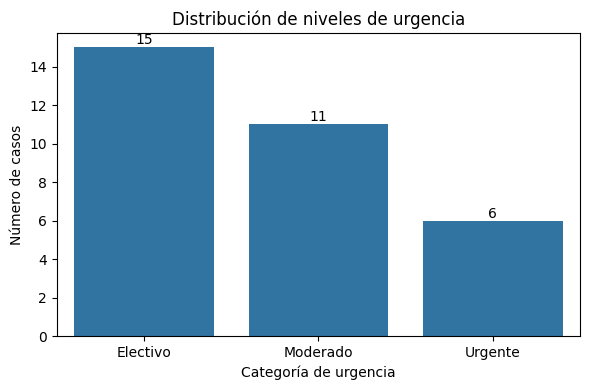

In [29]:
# [CELDA 5.2] Gráfico de barras: distribución de urgencias
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=conteo.index, y=conteo.values, order=orden, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Distribución de niveles de urgencia")
ax.set_xlabel("Categoría de urgencia"); ax.set_ylabel("Número de casos")
plt.tight_layout()
plt.savefig(os.path.join(SALIDA, "fig_distribucion_urgencias.png"), dpi=150)
plt.show()

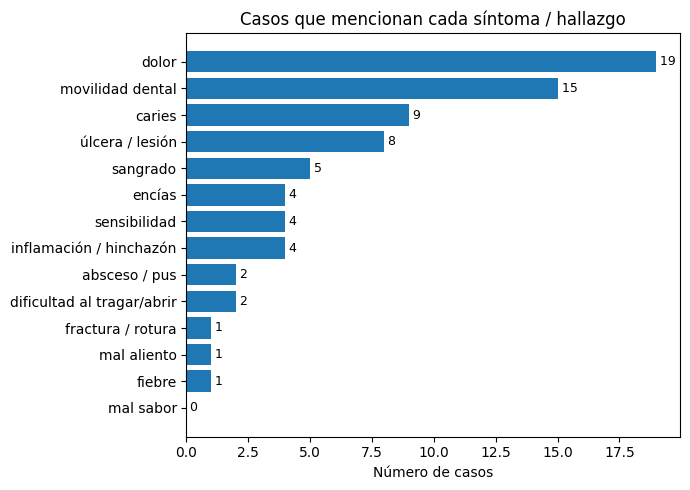

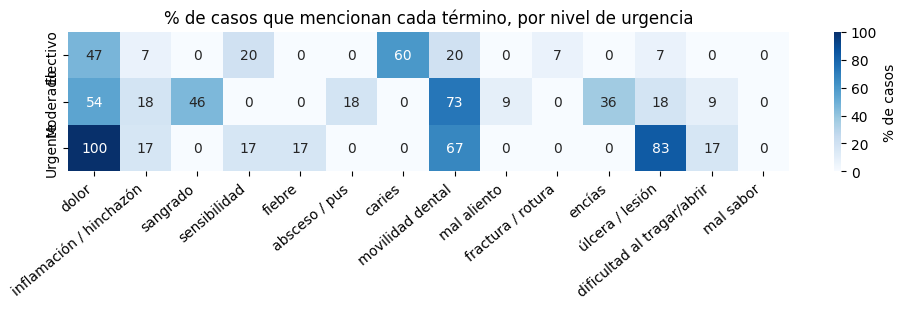


20 palabras más frecuentes (sin palabras vacías, solo para visualización):
[('dolor', 31), ('paciente', 30), ('dientes', 22), ('resultados', 22), ('clínicos', 22), ('durante', 20), ('sin', 19), ('movilidad', 18), ('reporta', 18), ('diente', 17), ('buena', 13), ('sondeo', 12), ('higiene', 12), ('bucal', 12), ('sangrado', 11), ('conclusiones', 10), ('clínicas', 10), ('percusión', 10), ('años', 10), ('positiva', 10)]


In [30]:
# [CELDA 5.3] Frecuencia de términos de síntomas (solo conteo descriptivo)
def sin_acentos(t):
    return "".join(c for c in unicodedata.normalize("NFD", t) if unicodedata.category(c) != "Mn")

TERMINOS = {
    "dolor": r"\bdolor",
    "inflamación / hinchazón": r"\b(inflamacion|inflamad\w*|hinchazon|hinchad\w*|edema)",
    "sangrado": r"\bsangr\w+",
    "sensibilidad": r"\bsensib\w+",
    "fiebre": r"\bfiebre",
    "absceso / pus": r"\b(absceso|pus|supuraci\w+)",
    "caries": r"\bcarie\w*",
    "movilidad dental": r"\bmovilidad|\bflojo|\bsuelto",
    "mal aliento": r"\bmal aliento|\bhalitosis",
    "fractura / rotura": r"\bfractur\w+|\brot[oa]\b",
    "encías": r"\bencia\w*",
    "úlcera / lesión": r"\bulcera\w*|\blesion\w*|\bllaga\w*",
    "dificultad al tragar/abrir": r"\btragar|\btrismo|\babrir la boca",
    "mal sabor": r"\bmal sabor|\bsabor desagradable",
}
base_ns = df_limpio["texto_limpio"].apply(sin_acentos)
frec = {k: int(base_ns.str.contains(p, regex=True).sum()) for k, p in TERMINOS.items()}
frec = pd.Series(frec).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(frec.index, frec.values)
for y, v in enumerate(frec.values):
    ax.text(v, y, f" {v}", va="center", fontsize=9)
ax.set_title("Casos que mencionan cada síntoma / hallazgo")
ax.set_xlabel("Número de casos")
plt.tight_layout()
plt.savefig(os.path.join(SALIDA, "fig_frecuencia_sintomas.png"), dpi=150)
plt.show()

# Porcentaje de casos con cada término, por clase
tabla = pd.DataFrame({k: base_ns.str.contains(p, regex=True) for k, p in TERMINOS.items()})
tabla["categoria"] = df_limpio["categoria_urgencia"].values
por_clase = (100 * tabla.groupby("categoria").mean(numeric_only=True)).reindex(orden).round(1)
fig, ax = plt.subplots(figsize=(10, 3.2))
sns.heatmap(por_clase, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% de casos"}, ax=ax)
ax.set_title("% de casos que mencionan cada término, por nivel de urgencia")
plt.xticks(rotation=40, ha="right"); plt.ylabel("")
plt.tight_layout()
plt.savefig(os.path.join(SALIDA, "fig_terminos_por_clase.png"), dpi=150)
plt.show()

# Palabras más frecuentes (con una lista mínima de palabras vacías, SOLO para esta gráfica)
VACIAS_EDA = set("de la el en y a los las un una con por que se del al para su es lo como más o pero sus le ya "
                 "este esta hace desde hasta entre muy sobre también".split())
palabras = Counter(w for t in df_limpio["texto_limpio"] for w in re.findall(r"[a-záéíóúüñ]+", t)
                   if w not in VACIAS_EDA and len(w) > 2)
print("\n20 palabras más frecuentes (sin palabras vacías, solo para visualización):")
print(palabras.most_common(20))

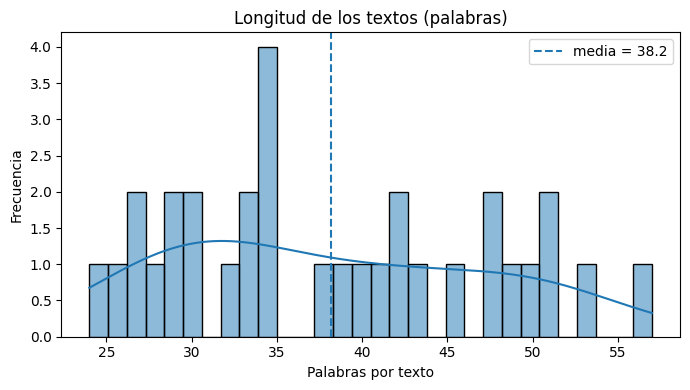

In [31]:
# [CELDA 5.4] Histograma de longitud de textos
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(n_pal, bins=30, kde=True, ax=ax)
ax.axvline(n_pal.mean(), linestyle="--", label=f"media = {n_pal.mean():.1f}")
ax.set_title("Longitud de los textos (palabras)")
ax.set_xlabel("Palabras por texto"); ax.set_ylabel("Frecuencia")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(SALIDA, "fig_histograma_longitud.png"), dpi=150)
plt.show()

### Interpretación de la Fase 5
- **Distribución de urgencias:** si una barra es mucho menor que las demás hay desbalance. Mira la razón mayoritaria/minoritaria impresa en 5.1: valores altos obligan a usar ponderación de clases y métricas por clase.
- **Frecuencia de síntomas:** muestra qué vocabulario domina. El mapa de calor por clase indica qué términos distinguen niveles de urgencia (por ejemplo, si *absceso* o *fiebre* aparecen más en *Urgente*). Es una descripción de los datos sintéticos, no evidencia clínica.
- **Histograma de longitud:** textos muy cortos darán pocas características a TF-IDF; textos muy largos pueden mezclar mucha información. Si la longitud difiere mucho entre clases, el modelo podría aprender la longitud en lugar del contenido.

## FASE 6. Preparación para entrenamiento

**Entrada X:** `texto_limpio` (síntomas en español). **Salida y:** `urgencia` (0, 1, 2).

Puntos clave para evitar resultados engañosos:
- **Sin fuga por duplicados casi idénticos.** Los datos sintéticos suelen repetir plantillas. Se agrupan los textos cuya similitud coseno (TF-IDF, sin usar etiquetas) supera un umbral, y **cada grupo completo va a una sola partición**. El umbral se endurece automáticamente si un grupo gigante lo vuelve inviable.
- **Estratificación por clase** con `StratifiedGroupKFold` (≈ 71.4 % / 14.3 % / 14.3 %, que es la aproximación a 70/15/15 que permiten los pliegues).
- **TF-IDF ajustado solo con entrenamiento.** Validación y prueba solo se transforman.
- No se usan diagnóstico, tratamiento ni respuesta del asistente como predictores.

In [32]:
# [CELDA 6.1] Validación de etiquetas y construcción de grupos
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

df_modelo = df_limpio[["id_caso", "texto_limpio", "urgencia", "categoria_urgencia"]].copy().reset_index(drop=True)
assert df_modelo["urgencia"].notna().all(), "Hay urgencias nulas"
df_modelo["urgencia"] = df_modelo["urgencia"].astype(int)
invalidas = ~df_modelo["urgencia"].isin([0, 1, 2])
assert not invalidas.any(), f"Etiquetas inválidas: {int(invalidas.sum())}"
print("Etiquetas verificadas: solo 0, 1 y 2.")
print(df_modelo["urgencia"].value_counts().sort_index())

def construir_grupos(textos, umbrales=(0.90, 0.95, 0.98, 1.0), max_frac=0.03):
    """Agrupa textos casi idénticos (componentes conexas por similitud coseno). No usa etiquetas."""
    Xg = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit_transform(textos)
    S = cosine_similarity(Xg)
    np.fill_diagonal(S, 0)
    for u in umbrales:
        n_g, etiquetas = connected_components(csr_matrix(S >= (u - 1e-9)), directed=False)
        mayor = int(np.bincount(etiquetas).max())
        if mayor <= max_frac * len(textos) or u == umbrales[-1]:
            return etiquetas, u, n_g, mayor

grupos, umbral_usado, n_grupos, mayor_grupo = construir_grupos(df_modelo["texto_limpio"].tolist())
print(f"\nUmbral de similitud usado: {umbral_usado} | grupos: {n_grupos} | grupo más grande: {mayor_grupo} registros")
registro["umbral_grupos"] = float(umbral_usado)
registro["n_grupos"] = int(n_grupos)
registro["mayor_grupo"] = int(mayor_grupo)

Etiquetas verificadas: solo 0, 1 y 2.
urgencia
0    15
1    11
2     6
Name: count, dtype: int64

Umbral de similitud usado: 1.0 | grupos: 32 | grupo más grande: 1 registros


In [33]:
# [CELDA 6.2] División 70/15/15 estratificada y agrupada
def dividir(df, y, grupos, n_splits, semilla):
    try:
        sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=semilla)
        return next(sgkf.split(df, y, grupos))
    except Exception as e:
        print("StratifiedGroupKFold no fue posible, se usa GroupShuffleSplit sin estratificar:", repr(e)[:150])
        gss = GroupShuffleSplit(n_splits=1, test_size=1 / n_splits, random_state=semilla)
        return next(gss.split(df, y, grupos))

y_all = df_modelo["urgencia"].values
idx_resto, idx_test = dividir(df_modelo, y_all, grupos, n_splits=7, semilla=SEED)       # ~14.3 % test
df_resto = df_modelo.iloc[idx_resto]
idx_tr_loc, idx_va_loc = dividir(df_resto, df_resto["urgencia"].values, grupos[idx_resto], n_splits=6, semilla=SEED)

df_train = df_resto.iloc[idx_tr_loc].reset_index(drop=True)
df_val = df_resto.iloc[idx_va_loc].reset_index(drop=True)
df_test = df_modelo.iloc[idx_test].reset_index(drop=True)

g_train = set(grupos[idx_resto][idx_tr_loc]); g_val = set(grupos[idx_resto][idx_va_loc]); g_test = set(grupos[idx_test])
assert not (g_train & g_val) and not (g_train & g_test) and not (g_val & g_test), "Hay grupos en más de una partición"
assert not (set(df_train.texto_limpio) & set(df_val.texto_limpio)), "Textos repetidos entre train y validation"
assert not (set(df_train.texto_limpio) & set(df_test.texto_limpio)), "Textos repetidos entre train y test"
assert not (set(df_val.texto_limpio) & set(df_test.texto_limpio)), "Textos repetidos entre validation y test"
assert len(df_train) + len(df_val) + len(df_test) == len(df_modelo)
print("Verificaciones superadas: sin grupos ni textos compartidos entre particiones.\n")

resumen_split = pd.DataFrame({
    "n": [len(df_train), len(df_val), len(df_test)],
    "% del total": [round(100 * len(d) / len(df_modelo), 1) for d in (df_train, df_val, df_test)],
}, index=["train", "validation", "test"])
for k in (0, 1, 2):
    resumen_split[MAPA_URGENCIA[k]] = [int((d["urgencia"] == k).sum()) for d in (df_train, df_val, df_test)]
display(resumen_split)

registro["n_train"], registro["n_val"], registro["n_test"] = len(df_train), len(df_val), len(df_test)
registro["split"] = resumen_split.to_dict()

Verificaciones superadas: sin grupos ni textos compartidos entre particiones.



,n,% del total,Electivo,Moderado,Urgente
train,22,68.8,10,8,4
validation,5,15.6,3,1,1
test,5,15.6,2,2,1


In [34]:
# [CELDA 6.3] TF-IDF ajustado solo con entrenamiento
import joblib

vectorizador = TfidfVectorizer(
    ngram_range=(1, 2),     # bigramas capturan "sin fiebre", "no presenta"
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    lowercase=True,
    strip_accents=None,     # se conservan los acentos del español
)
X_train = vectorizador.fit_transform(df_train["texto_limpio"])      # fit SOLO con train
X_val = vectorizador.transform(df_val["texto_limpio"])
X_test = vectorizador.transform(df_test["texto_limpio"])
y_train, y_val, y_test = df_train["urgencia"].values, df_val["urgencia"].values, df_test["urgencia"].values

print("Dimensiones X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
print("Tamaño del vocabulario (solo train):", len(vectorizador.vocabulary_))
for w in ("no", "sin", "dolor", "fiebre"):
    print(f"  '{w}' en el vocabulario:", w in vectorizador.vocabulary_)
joblib.dump(vectorizador, os.path.join(SALIDA, "tfidf_vectorizer.joblib"))
registro["vocabulario"] = len(vectorizador.vocabulary_)

Dimensiones X_train: (22, 241) | X_val: (5, 241) | X_test: (5, 241)
Tamaño del vocabulario (solo train): 241
  'no' en el vocabulario: True
  'sin' en el vocabulario: True
  'dolor' en el vocabulario: True
  'fiebre' en el vocabulario: False


### 6.4 Comprobación rápida de que los datos sirven para entrenar (solo validación)
Se entrenan tres modelos base con `class_weight="balanced"` y se evalúan **únicamente sobre validación**. El conjunto de prueba se reserva para la evaluación final. Esto no es el modelo definitivo; solo comprueba que el preprocesamiento produce una señal aprendible.

In [35]:
# [CELDA 6.4] Modelos base evaluados en validación
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, recall_score

modelos = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "Linear SVM": LinearSVC(class_weight="balanced", random_state=SEED),
    "Complement Naive Bayes": ComplementNB(),
}
nombres = [MAPA_URGENCIA[k] for k in (0, 1, 2)]
filas_res = []
for nombre, clf in modelos.items():
    clf.fit(X_train, y_train)
    pred = clf.predict(X_val)
    filas_res.append({
        "modelo": nombre,
        "exactitud": round(accuracy_score(y_val, pred), 4),
        "F1 macro": round(f1_score(y_val, pred, average="macro", zero_division=0), 4),
        "recall Urgente": round(recall_score(y_val, pred, labels=[2], average=None, zero_division=0)[0], 4),
    })
res_base = pd.DataFrame(filas_res)
display(res_base)

mejor = res_base.sort_values("F1 macro", ascending=False).iloc[0]["modelo"]
print("Informe por clase del mejor F1 macro:", mejor)
print(classification_report(y_val, modelos[mejor].predict(X_val), labels=[0, 1, 2],
                            target_names=nombres, zero_division=0))
registro["baseline_validacion"] = res_base.to_dict(orient="records")

,modelo,exactitud,F1 macro,recall Urgente
0,Logistic Regression,0.6,0.4889,0.0
1,Linear SVM,0.6,0.4333,0.0
2,Complement Naive Bayes,0.6,0.4333,0.0


Informe por clase del mejor F1 macro: Logistic Regression
              precision    recall  f1-score   support

    Electivo       1.00      0.67      0.80         3
    Moderado       0.50      1.00      0.67         1
     Urgente       0.00      0.00      0.00         1

    accuracy                           0.60         5
   macro avg       0.50      0.56      0.49         5
weighted avg       0.70      0.60      0.61         5



### Interpretación de la Fase 6
- Los `assert` confirman que **ningún grupo ni texto está en dos particiones**. Si el umbral final fue alto (0.98 o 1.0), significa que los grupos de casi-duplicados eran demasiado grandes para el umbral inferior; revisa en el informe que la partición sigue siendo razonable.
- La tabla de particiones debe mostrar proporciones cercanas a 71/14/14 y las tres clases presentes en cada partición.
- Las métricas base son de **validación** y sirven de referencia. Con datos sintéticos generados con plantillas, una exactitud muy alta puede reflejar el estilo de generación y no el rendimiento con pacientes reales. El *recall* de *Urgente* es la métrica más importante para este chatbot: un caso urgente clasificado como electivo es el error más costoso.
- El conjunto de prueba (`test.csv`) no se ha usado todavía.

## FASE 7. Exportación de archivos

Se generan los siete CSV en UTF-8 y se verifica cada uno releyéndolo. Además se crea un ZIP con todos los resultados (incluidos informe de errores de traducción, muestra de revisión, figuras y el vectorizador TF-IDF).

> Si abres los CSV en Excel y los acentos se ven mal, impórtalos indicando codificación UTF-8 (*Datos → Desde texto/CSV*).

In [36]:
# [CELDA 7.1] Exportar CSV
def guardar(df, nombre):
    ruta = os.path.join(SALIDA, nombre)
    df.to_csv(ruta, index=False, encoding="utf-8")
    comprobacion = pd.read_csv(ruta, encoding="utf-8")
    assert len(comprobacion) == len(df), f"{nombre}: el número de filas no coincide al releer"
    print(f"{nombre:24s} filas={len(df):5d} columnas={df.shape[1]:2d}")
    return ruta

# 1) Original: la conversación se serializa como texto JSON (conserva roles y contenido)
df_orig_export = df_original.copy()
df_orig_export[col_msgs] = df_orig_export[col_msgs].apply(lambda m: json.dumps(a_lista(m), ensure_ascii=False))
guardar(df_orig_export, "dataset_original.csv")

# 2) Extraído
cols_extraido = ["id_caso", "descripcion_original", "sintomas_originales", "urgencia", "categoria_urgencia",
                 "diagnostico_original", "motivo_consulta_original", "antecedentes_originales",
                 "estado_urgencia", "formato_user", "sintomas_fallback"]
guardar(df_extraido[cols_extraido], "dataset_extraido.csv")

# 3) Traducido
cols_trad = ["id_caso", "descripcion_original", "sintomas_originales", "descripcion_es", "sintomas_es",
             "urgencia", "categoria_urgencia", "alerta_traduccion"]
guardar(df_trad[cols_trad], "dataset_traducido.csv")

# 4) Limpio
cols_limpio = ["id_caso", "descripcion_es", "sintomas_es", "texto_limpio", "urgencia", "categoria_urgencia",
               "fuente_texto", "alerta_traduccion"]
guardar(df_limpio[cols_limpio], "dataset_limpio.csv")

# 5-7) Particiones
guardar(df_train, "train.csv")
guardar(df_val, "validation.csv")
guardar(df_test, "test.csv")

def empaquetar():
    ruta_zip = os.path.join(SALIDA, "resultados_chatbot_odontologico.zip")
    with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as z:
        for f in sorted(os.listdir(SALIDA)):
            if f.endswith(".zip") or f == "cache_traduccion.json":
                continue
            z.write(os.path.join(SALIDA, f), arcname=f)
    return ruta_zip

ruta_zip = empaquetar()
print("\nArchivos en la carpeta de salida:")
for f in sorted(os.listdir(SALIDA)):
    print(f"  {f:40s} {os.path.getsize(os.path.join(SALIDA, f)) / 1024:9.1f} KB")

dataset_original.csv     filas= 2494 columnas= 1
dataset_extraido.csv     filas= 2494 columnas=11
dataset_traducido.csv    filas= 2494 columnas= 8
dataset_limpio.csv       filas=   32 columnas= 8
train.csv                filas=   22 columnas= 4
validation.csv           filas=    5 columnas= 4
test.csv                 filas=    5 columnas= 4

Archivos en la carpeta de salida:
  cache_traduccion.json                         62.9 KB
  dataset_extraido.csv                        2121.6 KB
  dataset_limpio.csv                            44.5 KB
  dataset_original.csv                        5490.1 KB
  dataset_traducido.csv                       3596.2 KB
  errores_traduccion.csv                         0.5 KB
  fig_distribucion_urgencias.png                29.6 KB
  fig_frecuencia_sintomas.png                   59.8 KB
  fig_histograma_longitud.png                   44.1 KB
  fig_terminos_por_clase.png                   101.9 KB
  muestra_revision_manual.csv                   43.2 KB
  resu

In [37]:
# [CELDA 7.2] Descarga desde Colab
DESCARGAR_INDIVIDUALES = False     # True = descarga también cada CSV por separado

try:
    from google.colab import files
    files.download(ruta_zip)
    if DESCARGAR_INDIVIDUALES:
        for f in ["dataset_original.csv", "dataset_extraido.csv", "dataset_traducido.csv", "dataset_limpio.csv",
                  "train.csv", "validation.csv", "test.csv"]:
            files.download(os.path.join(SALIDA, f))
except ImportError:
    print("No estás en Colab. Los archivos están en:", SALIDA)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Interpretación de la Fase 7
- Cada línea indica el número de filas verificado al releer el archivo; deben coincidir con las cifras de las fases anteriores (`dataset_original.csv` = registros descargados; `train + validation + test` = `dataset_limpio.csv`).
- También puedes descargar desde el panel de archivos de Colab (icono de carpeta → `salida`).

## FASE 8. Documentación académica

La celda siguiente **genera el resumen técnico con las cifras reales de tu ejecución**: lee el diccionario `registro` y los DataFrames. Si alguna cifra no existe (por ejemplo, porque saltaste una fase), aparece como `N/D`. Se guarda como `resumen_tecnico.md` (se puede pegar en Word/Docs).

Los datos descriptivos del dataset (autor, licencia, características) provienen de su ficha en Hugging Face; las limitaciones citadas como "según la ficha" son las que declara su autor.

In [38]:
# [CELDA 8.1] Generación del resumen técnico
try:
    from IPython.display import Markdown, display as _display
except ImportError:
    Markdown = lambda x: x
    _display = print

def n(k):
    v = registro.get(k)
    return f"{v:,}" if isinstance(v, (int, np.integer)) else "N/D"

def tabla_md(df):
    try:
        return df.to_markdown(index=False)
    except Exception:
        return "```\n" + df.to_string(index=False) + "\n```"

# Distribución de clases
dist_f = df_limpio["categoria_urgencia"].value_counts().reindex(orden).fillna(0).astype(int)
tabla_dist = pd.DataFrame({"Categoría": orden, "Casos": dist_f.values,
                           "Porcentaje": [f"{100 * v / dist_f.sum():.2f} %" for v in dist_f.values]})

# Tabla antes / después
bajas_txt = registro.get("bajas", {})
tabla_cmp = pd.DataFrame({
    "Etapa": [
        "Registros descargados (original)",
        "Con etiqueta de urgencia identificada (Fase 2)",
        "Pendientes de revisión de urgencia (Fase 2)",
        "Traducidos por completo (Fase 3)",
        "Traducción fallida (Fase 3)",
        "Al iniciar la limpieza (Fase 4)",
        "Registros válidos tras el preprocesamiento",
        "Conjunto de entrenamiento",
        "Conjunto de validación",
        "Conjunto de prueba",
    ],
    "Registros": [n("n_original"), n("n_urgencia_ok"), n("n_urgencia_pendiente"), n("n_traducidos_ok"),
                  n("n_traduccion_fallida"), n("n_inicio_limpieza"), n("n_final"),
                  n("n_train"), n("n_val"), n("n_test")],
})
tabla_bajas = pd.DataFrame({"Motivo de exclusión": list(bajas_txt.keys()),
                            "Registros": [f"{v:,}" for v in bajas_txt.values()]}) if bajas_txt else pd.DataFrame({"Motivo de exclusión": [], "Registros": []})

base = pd.DataFrame(registro.get("baseline_validacion", []))
texto_base = ("\n\nComo verificación de que los datos son aprendibles, se entrenaron modelos base evaluados únicamente sobre validación:\n\n"
              + tabla_md(base)) if len(base) else ""

informe = f"""# Resumen técnico del procesamiento de datos

## 1. Descripción del dataset
`Wildstash/dental-treatment-planning-2.5k` (Hugging Face) es un conjunto de casos clínicos odontológicos **sintéticos** en inglés, publicado en formato JSONL con licencia Apache 2.0. Cada ejemplo es una conversación de tres mensajes (`system`, `user`, `assistant`). El mensaje `user` describe el caso (datos demográficos, motivo de consulta, historia, exploración, hallazgos radiográficos y antecedentes médicos) y el mensaje `assistant` contiene una valoración estructurada (diagnóstico, etiología, urgencia, plan de manejo, antibióticos, seguimiento, consejos y fuente de guía). Según su ficha, la urgencia se codifica como 0 = electivo, 1 = moderado y 2 = urgente.

## 2. Justificación de su selección
Es de acceso abierto, está orientado a triaje y diagnóstico dental, incluye una etiqueta explícita de urgencia con tres niveles y no contiene datos reales de pacientes (no hay información de salud protegida), lo que lo hace adecuado para un proyecto académico.

## 3. Estructura y características
Una columna de conversaciones (`{col_msgs}`) con roles `system`, `user` y `assistant`. El prompt de sistema es una instrucción para el asistente y no forma parte de los datos clínicos. Longitud media del mensaje del usuario: {stats['palabras_user'].mean():.1f} palabras (valor real calculado en la Fase 1).

## 4. Cantidad inicial de registros
**{n('n_original')}** registros. Conversaciones completas duplicadas: {n('n_duplicados_originales')}. Mensajes `user` repetidos: {n('n_user_duplicados')}.

## 5. Procedimiento de extracción
Se descartó el prompt de sistema. De `user` se retiró el prefijo `PATIENT:` para obtener la descripción original y se separaron las secciones por encabezados. Como síntomas se tomaron el motivo de consulta y la historia; la exploración y los hallazgos radiográficos se excluyeron de los síntomas porque son observaciones del clínico y el chatbot solo recibirá lo que escriba el paciente. La urgencia se leyó de la etiqueta explícita del mensaje `assistant` (primero JSON, después patrones `Urgency: n`), sin inferirla de palabras clave; las etiquetas ausentes o contradictorias se marcaron como pendientes de revisión ({n('n_urgencia_pendiente')} registros). Registros con mensaje `user` sin secciones reconocibles: {n('n_sin_secciones')}.

## 6. Método de traducción
Traducción automática neuronal inglés→español con el modelo MarianMT `Helsinki-NLP/opus-mt-en-es`. Los textos se segmentaron en oraciones, se tradujeron por lotes (con caché y reintentos ante errores) y se reensamblaron. Se aplicó un control automático por oración (pérdida o adición de negaciones, cambio de cifras, longitud atípica, traducción vacía o sin traducir). Oraciones únicas traducidas: {n('n_segmentos_unicos')}; con alerta de calidad: {n('n_segmentos_alerta')}; casos con alguna alerta: {n('n_casos_alerta_traduccion')}. Se exportó una muestra aleatoria para revisión manual (`muestra_revision_manual.csv`). Las etiquetas de urgencia no se modificaron (verificado con una aserción). No se realizó validación clínica de la traducción por un odontólogo salvo que se haya hecho con la muestra de revisión manual.

## 7. Técnicas de limpieza
Decodificación de entidades HTML y eliminación de etiquetas, normalización Unicode (NFC), minúsculas, eliminación de caracteres especiales (se conservan letras con acentos, ñ, ü, dígitos y puntuación básica), normalización de espacios y de puntuación repetida. No se eliminaron palabras vacías para conservar negaciones y términos clínicos (`no`, `sin`, `nunca`, `dolor`, `fiebre`, `inflamación`, `sangrado`); se verificó su frecuencia antes y después.

## 8. Tratamiento de datos faltantes, duplicados y conflictos
Se excluyeron los registros sin etiqueta válida, con traducción fallida, con texto vacío o incompleto (menos de {MIN_PALABRAS} palabras), los duplicados exactos (texto y urgencia) y los textos idénticos con urgencias distintas. No se imputó ningún valor.

{tabla_md(tabla_bajas)}

## 9. Distribución de las clases (conjunto limpio)
{tabla_md(tabla_dist)}

Razón entre la clase mayoritaria y la minoritaria: {registro.get('razon_desbalance', 'N/D')}. Longitud media de los textos: {registro.get('long_media_palabras', 'N/D')} palabras.

## 10. Método de partición
División estratificada por clase y agrupada con `StratifiedGroupKFold` (semilla {SEED}). Los textos con similitud coseno (TF-IDF, sin usar etiquetas) mayor o igual a {registro.get('umbral_grupos', 'N/D')} se agruparon ({n('n_grupos')} grupos; el mayor con {n('mayor_grupo')} registros) y cada grupo se asignó a una sola partición para evitar fuga por casos clínicamente equivalentes. Resultado: entrenamiento {n('n_train')}, validación {n('n_val')} y prueba {n('n_test')} registros.

## 11. Preparación para el entrenamiento
Entrada: `texto_limpio`; salida: `urgencia` (0, 1, 2). Vectorización TF-IDF con unigramas y bigramas (`min_df=2`, `max_df=0.95`, `sublinear_tf=True`), ajustada **solo con entrenamiento**; vocabulario resultante: {n('vocabulario')} términos. No se emplearon diagnóstico, tratamiento ni respuesta del asistente como predictores.{texto_base}

## 12. Tabla comparativa de registros antes y después del preprocesamiento
{tabla_md(tabla_cmp)}

## 13. Limitaciones
- Según la ficha del dataset: los casos son sintéticos (no reflejan pacientes reales), cubren odontología general, fueron revisados por expertos pero no probados clínicamente y pueden reflejar sesgos de generación.
- El dataset original está en inglés; la versión en español proviene de traducción automática, que puede alterar matices clínicos aunque se aplicaron controles automáticos.
- Las etiquetas de urgencia fueron asignadas durante la generación sintética, no por triaje real; las métricas obtenidas con estos datos no garantizan el rendimiento con pacientes reales.
- Los textos generados por plantillas son más homogéneos que el lenguaje coloquial de los pacientes; el modelo podría no generalizar a faltas de ortografía, regionalismos o descripciones vagas.
- Si hay desbalance entre clases, el modelo puede rendir peor en la clase minoritaria; el error más costoso es clasificar un caso urgente como electivo.
- El sistema ofrece orientación inicial y clasificación de urgencia; no sustituye el diagnóstico de un profesional odontológico.
"""

ruta_md = os.path.join(SALIDA, "resumen_tecnico.md")
with open(ruta_md, "w", encoding="utf-8") as f:
    f.write(informe)
ruta_zip = empaquetar()          # vuelve a empaquetar incluyendo el resumen
print("Resumen guardado en:", ruta_md)
_display(Markdown(informe))

Resumen guardado en: /content/salida/resumen_tecnico.md


# Resumen técnico del procesamiento de datos

## 1. Descripción del dataset
`Wildstash/dental-treatment-planning-2.5k` (Hugging Face) es un conjunto de casos clínicos odontológicos **sintéticos** en inglés, publicado en formato JSONL con licencia Apache 2.0. Cada ejemplo es una conversación de tres mensajes (`system`, `user`, `assistant`). El mensaje `user` describe el caso (datos demográficos, motivo de consulta, historia, exploración, hallazgos radiográficos y antecedentes médicos) y el mensaje `assistant` contiene una valoración estructurada (diagnóstico, etiología, urgencia, plan de manejo, antibióticos, seguimiento, consejos y fuente de guía). Según su ficha, la urgencia se codifica como 0 = electivo, 1 = moderado y 2 = urgente.

## 2. Justificación de su selección
Es de acceso abierto, está orientado a triaje y diagnóstico dental, incluye una etiqueta explícita de urgencia con tres niveles y no contiene datos reales de pacientes (no hay información de salud protegida), lo que lo hace adecuado para un proyecto académico.

## 3. Estructura y características
Una columna de conversaciones (`messages`) con roles `system`, `user` y `assistant`. El prompt de sistema es una instrucción para el asistente y no forma parte de los datos clínicos. Longitud media del mensaje del usuario: 66.2 palabras (valor real calculado en la Fase 1).

## 4. Cantidad inicial de registros
**2,494** registros. Conversaciones completas duplicadas: 364. Mensajes `user` repetidos: 384.

## 5. Procedimiento de extracción
Se descartó el prompt de sistema. De `user` se retiró el prefijo `PATIENT:` para obtener la descripción original y se separaron las secciones por encabezados. Como síntomas se tomaron el motivo de consulta y la historia; la exploración y los hallazgos radiográficos se excluyeron de los síntomas porque son observaciones del clínico y el chatbot solo recibirá lo que escriba el paciente. La urgencia se leyó de la etiqueta explícita del mensaje `assistant` (primero JSON, después patrones `Urgency: n`), sin inferirla de palabras clave; las etiquetas ausentes o contradictorias se marcaron como pendientes de revisión (200 registros). Registros con mensaje `user` sin secciones reconocibles: 200.

## 6. Método de traducción
Traducción automática neuronal inglés→español con el modelo MarianMT `Helsinki-NLP/opus-mt-en-es`. Los textos se segmentaron en oraciones, se tradujeron por lotes (con caché y reintentos ante errores) y se reensamblaron. Se aplicó un control automático por oración (pérdida o adición de negaciones, cambio de cifras, longitud atípica, traducción vacía o sin traducir). Oraciones únicas traducidas: N/D; con alerta de calidad: N/D; casos con alguna alerta: N/D. Se exportó una muestra aleatoria para revisión manual (`muestra_revision_manual.csv`). Las etiquetas de urgencia no se modificaron (verificado con una aserción). No se realizó validación clínica de la traducción por un odontólogo salvo que se haya hecho con la muestra de revisión manual.

## 7. Técnicas de limpieza
Decodificación de entidades HTML y eliminación de etiquetas, normalización Unicode (NFC), minúsculas, eliminación de caracteres especiales (se conservan letras con acentos, ñ, ü, dígitos y puntuación básica), normalización de espacios y de puntuación repetida. No se eliminaron palabras vacías para conservar negaciones y términos clínicos (`no`, `sin`, `nunca`, `dolor`, `fiebre`, `inflamación`, `sangrado`); se verificó su frecuencia antes y después.

## 8. Tratamiento de datos faltantes, duplicados y conflictos
Se excluyeron los registros sin etiqueta válida, con traducción fallida, con texto vacío o incompleto (menos de 4 palabras), los duplicados exactos (texto y urgencia) y los textos idénticos con urgencias distintas. No se imputó ningún valor.

| Motivo de exclusión                                     | Registros   |
|:--------------------------------------------------------|:------------|
| Sin etiqueta de urgencia válida (pendiente de revisión) | 200         |
| Traducción fallida                                      | 0           |
| Texto vacío tras la limpieza                            | 0           |
| Texto incompleto (< 4 palabras)                         | 0           |
| Duplicado exacto (texto + urgencia)                     | 2,259       |
| Texto idéntico con urgencias distintas (conflicto)      | 3           |

## 9. Distribución de las clases (conjunto limpio)
| Categoría   |   Casos | Porcentaje   |
|:------------|--------:|:-------------|
| Electivo    |      15 | 46.88 %      |
| Moderado    |      11 | 34.38 %      |
| Urgente     |       6 | 18.75 %      |

Razón entre la clase mayoritaria y la minoritaria: 2.5. Longitud media de los textos: 38.2 palabras.

## 10. Método de partición
División estratificada por clase y agrupada con `StratifiedGroupKFold` (semilla 42). Los textos con similitud coseno (TF-IDF, sin usar etiquetas) mayor o igual a 1.0 se agruparon (32 grupos; el mayor con 1 registros) y cada grupo se asignó a una sola partición para evitar fuga por casos clínicamente equivalentes. Resultado: entrenamiento 22, validación 5 y prueba 5 registros.

## 11. Preparación para el entrenamiento
Entrada: `texto_limpio`; salida: `urgencia` (0, 1, 2). Vectorización TF-IDF con unigramas y bigramas (`min_df=2`, `max_df=0.95`, `sublinear_tf=True`), ajustada **solo con entrenamiento**; vocabulario resultante: 241 términos. No se emplearon diagnóstico, tratamiento ni respuesta del asistente como predictores.

Como verificación de que los datos son aprendibles, se entrenaron modelos base evaluados únicamente sobre validación:

| modelo                 |   exactitud |   F1 macro |   recall Urgente |
|:-----------------------|------------:|-----------:|-----------------:|
| Logistic Regression    |         0.6 |     0.4889 |                0 |
| Linear SVM             |         0.6 |     0.4333 |                0 |
| Complement Naive Bayes |         0.6 |     0.4333 |                0 |

## 12. Tabla comparativa de registros antes y después del preprocesamiento
| Etapa                                          | Registros   |
|:-----------------------------------------------|:------------|
| Registros descargados (original)               | 2,494       |
| Con etiqueta de urgencia identificada (Fase 2) | 2,294       |
| Pendientes de revisión de urgencia (Fase 2)    | 200         |
| Traducidos por completo (Fase 3)               | N/D         |
| Traducción fallida (Fase 3)                    | N/D         |
| Al iniciar la limpieza (Fase 4)                | 2,494       |
| Registros válidos tras el preprocesamiento     | 32          |
| Conjunto de entrenamiento                      | 22          |
| Conjunto de validación                         | 5           |
| Conjunto de prueba                             | 5           |

## 13. Limitaciones
- Según la ficha del dataset: los casos son sintéticos (no reflejan pacientes reales), cubren odontología general, fueron revisados por expertos pero no probados clínicamente y pueden reflejar sesgos de generación.
- El dataset original está en inglés; la versión en español proviene de traducción automática, que puede alterar matices clínicos aunque se aplicaron controles automáticos.
- Las etiquetas de urgencia fueron asignadas durante la generación sintética, no por triaje real; las métricas obtenidas con estos datos no garantizan el rendimiento con pacientes reales.
- Los textos generados por plantillas son más homogéneos que el lenguaje coloquial de los pacientes; el modelo podría no generalizar a faltas de ortografía, regionalismos o descripciones vagas.
- Si hay desbalance entre clases, el modelo puede rendir peor en la clase minoritaria; el error más costoso es clasificar un caso urgente como electivo.
- El sistema ofrece orientación inicial y clasificación de urgencia; no sustituye el diagnóstico de un profesional odontológico.


In [39]:
# [CELDA 8.2] Descargar el resumen y el ZIP final
try:
    from google.colab import files
    files.download(ruta_md)
    files.download(ruta_zip)
except ImportError:
    print("No estás en Colab. Archivos en:", SALIDA)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Cierre
Con esto quedan listos `train.csv`, `validation.csv` y `test.csv` para entrenar el clasificador. Siguientes pasos naturales: ajustar hiperparámetros en validación, evaluar **una sola vez** en `test.csv` (priorizando el *recall* de *Urgente*), y probar el modelo con frases escritas por personas reales, no generadas por plantilla.